# E2 - So sánh MSA và tokenization trên CIFAR-10

In [1]:
import math
import time

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang dùng: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Có thể giảm các giá trị này để chạy thử nhanh hơn.
TRAIN_SAMPLES = 10_000  # Số ảnh dùng để huấn luyện; tăng có thể cải thiện khả năng học nhưng làm chạy lâu hơn.
TEST_SAMPLES = 2_000  # Số ảnh dùng để đánh giá; tăng giúp accuracy đáng tin cậy hơn nhưng đánh giá lâu hơn.
BATCH_SIZE = 64  # Số ảnh trong một batch; tăng thường tốn nhiều bộ nhớ hơn, giảm thì tốn thời gian hơn.
EPOCHS = 20  # Số lượt mô hình học qua toàn bộ tập train; tăng thường cải thiện việc học nhưng chạy lâu hơn.
PIXEL_MICROBATCH_SIZE = 8  # Số ảnh xử lý cùng lúc riêng cho Pixel; giảm để tiết kiệm VRAM, tăng có thể nhanh hơn nếu đủ VRAM.

Thiết bị đang dùng: cuda
GPU: Tesla T4


In [2]:
class CustomMSA(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim phải chia hết cho num_heads"

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = 1.0 / math.sqrt(self.head_dim)

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        batch_size, num_tokens, _ = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(batch_size, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)

        attn_scores = torch.matmul(q, k.transpose(-2, -1)) * self.scale
        attn_weights = self.dropout(self.softmax(attn_scores))
        attn_output = torch.matmul(attn_weights, v)

        attn_output = attn_output.transpose(1, 2).contiguous().view(
            batch_size, num_tokens, self.embed_dim
        )
        return self.out_proj(attn_output)


class PyTorchMSA(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        self.mha = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )

    def forward(self, x):
        attn_output, _ = self.mha(x, x, x)
        return attn_output


class PatchTokenization(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3, embed_dim=64):
        super().__init__()
        self.patch_size = patch_size
        patch_dim = in_channels * patch_size * patch_size
        self.proj = nn.Linear(patch_dim, embed_dim)

    def forward(self, x):
        batch_size, channels, _, _ = x.shape
        patch_size = self.patch_size
        x = x.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
        x = x.contiguous().view(batch_size, channels, -1, patch_size * patch_size)
        x = x.permute(0, 2, 1, 3).contiguous().view(
            batch_size, -1, channels * patch_size * patch_size
        )
        return self.proj(x)


class PixelTokenization(nn.Module):
    def __init__(self, in_channels=3, embed_dim=64):
        super().__init__()
        self.proj = nn.Linear(in_channels, embed_dim)

    def forward(self, x):
        batch_size, channels, height, width = x.shape
        x = x.reshape(batch_size, channels, height * width).permute(0, 2, 1)
        return self.proj(x)


class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, msa_type="custom", mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)

        if msa_type == "custom":
            self.msa = CustomMSA(embed_dim, num_heads, dropout)
        elif msa_type == "pytorch":
            self.msa = PyTorchMSA(embed_dim, num_heads, dropout)
        else:
            raise ValueError("msa_type phải là 'custom' hoặc 'pytorch'")

        self.norm2 = nn.LayerNorm(embed_dim)
        hidden_dim = int(embed_dim * mlp_ratio)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.msa(self.norm1(x))
        return x + self.ffn(self.norm2(x))


class SmallViTClassifier(nn.Module):
    def __init__(
        self,
        tokenize_mode="patch",
        msa_type="custom",
        img_size=32,
        in_channels=3,
        embed_dim=64,
        num_heads=4,
        num_classes=10,
    ):
        super().__init__()

        if tokenize_mode == "patch":
            patch_size = 4
            self.tokenizer = PatchTokenization(
                img_size, patch_size, in_channels, embed_dim
            )
            num_tokens = (img_size // patch_size) ** 2
        elif tokenize_mode == "pixel":
            self.tokenizer = PixelTokenization(in_channels, embed_dim)
            num_tokens = img_size * img_size
        else:
            raise ValueError("tokenize_mode phải là 'patch' hoặc 'pixel'")

        self.pos_embedding = nn.Parameter(torch.zeros(1, num_tokens, embed_dim))
        self.encoder = TransformerEncoderBlock(embed_dim, num_heads, msa_type)
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        x = self.tokenizer(x) + self.pos_embedding
        x = self.encoder(x)
        x = self.norm(x).mean(dim=1)
        return self.head(x)

In [3]:
def train_and_evaluate(
    model,
    train_loader,
    test_loader,
    epochs=5,
    lr=1e-3,
    microbatch_size=None,
    experiment_name="Model",
):
    if microbatch_size is not None and microbatch_size <= 0:
        raise ValueError("microbatch_size phải lớn hơn 0")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    training_start = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        print(f"{experiment_name} - Epoch {epoch + 1}/{epochs}")
        progress_interval = max(1, len(train_loader) // 20)

        for batch_index, (images, labels) in enumerate(train_loader, start=1):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            chunk_size = microbatch_size or images.size(0)
            batch_loss = 0.0
            for start in range(0, images.size(0), chunk_size):
                end = start + chunk_size
                chunk_images = images[start:end]
                chunk_labels = labels[start:end]
                outputs = model(chunk_images)
                loss = criterion(outputs, chunk_labels)
                weighted_loss = loss * (chunk_labels.size(0) / images.size(0))
                weighted_loss.backward()
                batch_loss += weighted_loss.detach().item()

            optimizer.step()
            total_loss += batch_loss
            if batch_index % progress_interval == 0 or batch_index == len(train_loader):
                print(
                    f"  Batch {batch_index}/{len(train_loader)} - loss={batch_loss:.4f}",
                    flush=True,
                )

        print(f"Epoch {epoch + 1}/{epochs} - loss trung bình mỗi batch: {total_loss / len(train_loader):.4f}")

    training_time = time.time() - training_start

    model.eval()
    correct = 0
    total = 0
    confusion_matrix = torch.zeros(10, 10, dtype=torch.int64)
    chunk_size = microbatch_size or BATCH_SIZE
    print(f"{experiment_name} - Đánh giá")
    eval_progress_interval = max(1, len(test_loader) // 10)
    with torch.inference_mode():
        for batch_index, (images, labels) in enumerate(test_loader, start=1):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            for start in range(0, images.size(0), chunk_size):
                end = start + chunk_size
                outputs = model(images[start:end])
                chunk_labels = labels[start:end]
                predicted = outputs.argmax(dim=1)
                total += chunk_labels.size(0)
                correct += (predicted == chunk_labels).sum().item()
                counts = torch.bincount(
                    chunk_labels * 10 + predicted, minlength=100
                ).reshape(10, 10)
                confusion_matrix += counts.cpu()
            if batch_index % eval_progress_interval == 0 or batch_index == len(test_loader):
                print(f"  Batch {batch_index}/{len(test_loader)}", flush=True)

    accuracy = 100.0 * correct / total
    return accuracy, training_time, confusion_matrix.numpy()

In [8]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

train_subset = Subset(train_dataset, range(min(TRAIN_SAMPLES, len(train_dataset))))
test_subset = Subset(test_dataset, range(min(TEST_SAMPLES, len(test_dataset))))
use_pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=use_pin_memory,
)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=use_pin_memory,
)

print(f"Số ảnh train: {len(train_subset):,} | Số ảnh test: {len(test_subset):,}")

Số ảnh train: 10,000 | Số ảnh test: 2,000


In [5]:
experiments = [
    {"name": "Custom MSA + Patch (4x4)", "msa": "custom", "token": "patch"},
    {"name": "PyTorch MSA + Patch (4x4)", "msa": "pytorch", "token": "patch"},
    {"name": "Custom MSA + Pixel (1x1)", "msa": "custom", "token": "pixel"},
]

results = []
for experiment in experiments:
    print(f"\nĐang chạy: {experiment['name']}")
    model = SmallViTClassifier(
        tokenize_mode=experiment["token"],
        msa_type=experiment["msa"],
        img_size=32,
        in_channels=3,
        embed_dim=64,
        num_heads=4,
    )
    microbatch_size = PIXEL_MICROBATCH_SIZE if experiment["token"] == "pixel" else None
    accuracy, training_time, confusion_matrix = train_and_evaluate(
        model,
        train_loader,
        test_loader,
        epochs=EPOCHS,
        microbatch_size=microbatch_size,
        experiment_name=experiment["name"],
    )
    results.append((experiment["name"], accuracy, training_time, confusion_matrix))
    print(f"Kết quả: accuracy={accuracy:.2f}% | thời gian train={training_time:.2f}s")

print(f"\n{'Cấu hình Mô hình':<35} | {'Accuracy (%)':<15} | {'Thời gian train (s)':<20}")
print("-" * 80)
for name, accuracy, training_time, _ in results:
    print(f"{name:<35} | {accuracy:<15.2f} | {training_time:<20.2f}")


Đang chạy: Custom MSA + Patch (4x4)
Custom MSA + Patch (4x4) - Epoch 1/20
  Batch 7/157 - loss=2.3188
  Batch 14/157 - loss=2.0674
  Batch 21/157 - loss=2.0903
  Batch 28/157 - loss=1.9447
  Batch 35/157 - loss=2.1196
  Batch 42/157 - loss=1.9341
  Batch 49/157 - loss=1.9255
  Batch 56/157 - loss=2.1065
  Batch 63/157 - loss=2.0847
  Batch 70/157 - loss=1.9581
  Batch 77/157 - loss=1.8067
  Batch 84/157 - loss=1.9370
  Batch 91/157 - loss=1.9683
  Batch 98/157 - loss=1.8748
  Batch 105/157 - loss=1.8295
  Batch 112/157 - loss=1.7925
  Batch 119/157 - loss=1.8810
  Batch 126/157 - loss=1.7538
  Batch 133/157 - loss=1.8358
  Batch 140/157 - loss=1.9078
  Batch 147/157 - loss=1.7889
  Batch 154/157 - loss=1.9033
  Batch 157/157 - loss=1.8755
Epoch 1/20 - loss trung bình mỗi batch: 1.9725
Custom MSA + Patch (4x4) - Epoch 2/20
  Batch 7/157 - loss=1.8990
  Batch 14/157 - loss=1.7100
  Batch 21/157 - loss=1.8083
  Batch 28/157 - loss=1.7964
  Batch 35/157 - loss=1.7627
  Batch 42/157 - loss

In [9]:
metric_results = []
for name, _, _, matrix in results:
    matrix = torch.as_tensor(matrix, dtype=torch.float64)
    true_positive = matrix.diag()
    actual_count = matrix.sum(dim=1)
    predicted_count = matrix.sum(dim=0)

    precision_per_class = true_positive / predicted_count.clamp(min=1)
    recall_per_class = true_positive / actual_count.clamp(min=1)
    f1_per_class = torch.where(
        precision_per_class + recall_per_class > 0,
        2 * precision_per_class * recall_per_class
        / (precision_per_class + recall_per_class).clamp(min=1e-12),
        torch.zeros_like(true_positive),
    )

    metric_results.append((
        name,
        precision_per_class.mean().item(),
        recall_per_class.mean().item(),
        f1_per_class.mean().item(),
    ))

print("Macro average per experiment:")
print(f"{'Experiment':<35} {'Precision':>10} {'Recall':>10} {'F1-score':>10}")
print("-" * 69)
for name, precision, recall, f1_score in metric_results:
    print(f"{name:<35} {precision:>10.4f} {recall:>10.4f} {f1_score:>10.4f}")

Macro average per experiment:
Experiment                           Precision     Recall   F1-score
---------------------------------------------------------------------
Custom MSA + Patch (4x4)                0.5183     0.5249     0.5156
PyTorch MSA + Patch (4x4)               0.5101     0.5128     0.5068
Custom MSA + Pixel (1x1)                0.4510     0.4466     0.4412


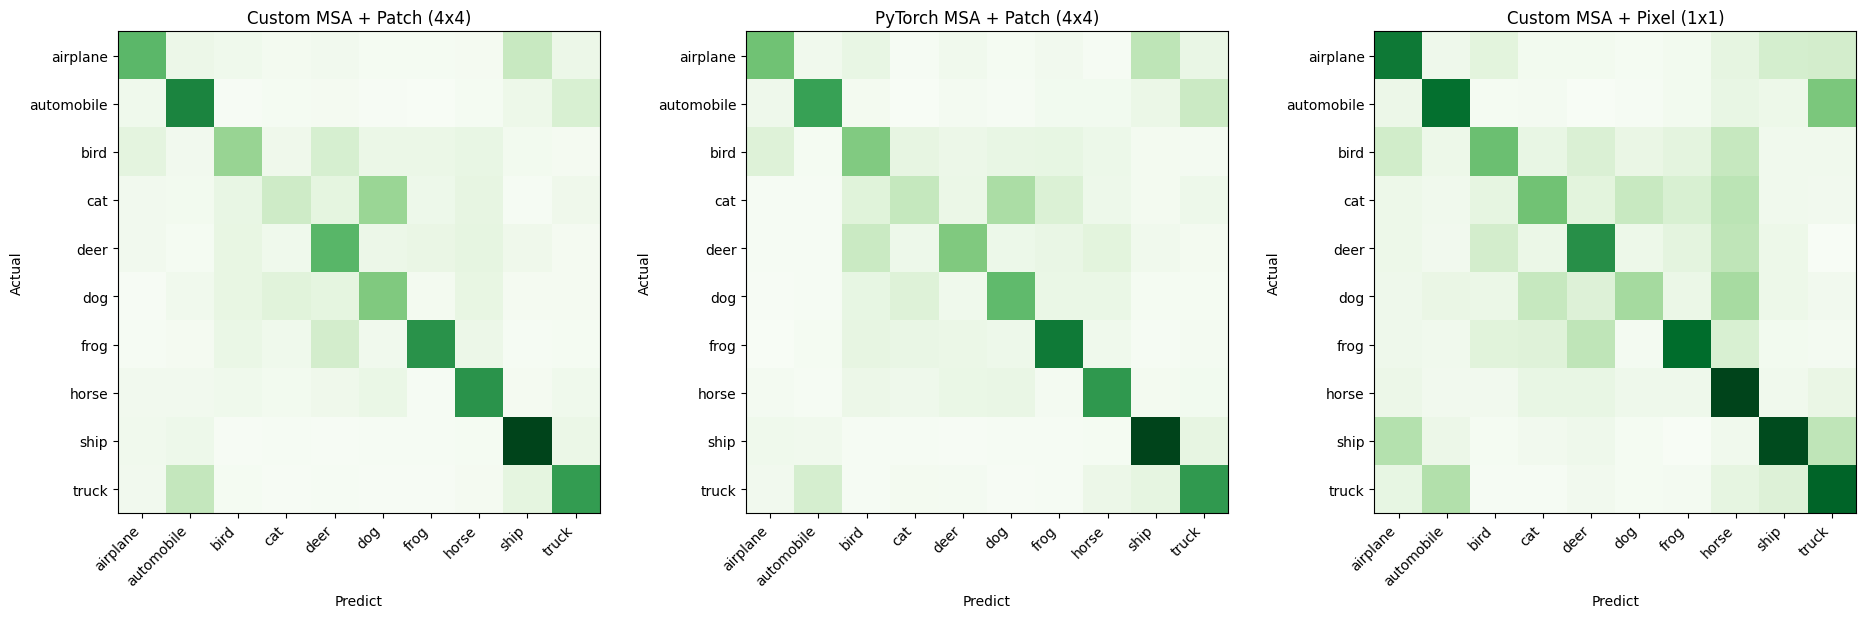

In [18]:
import matplotlib.pyplot as plt

class_names = test_dataset.classes
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (name, _, _, matrix) in zip(axes, results):
    image = ax.imshow(matrix, cmap="Greens")
    ax.set_title(name)
    ax.set_xlabel("Predict")
    ax.set_ylabel("Actual")
    ax.set_xticks(range(10), class_names, rotation=45, ha="right")
    ax.set_yticks(range(10), class_names)

#fig.colorbar(image, ax=axes, shrink=0.6, label="Amount")
plt.tight_layout()
plt.show()